<a href="https://colab.research.google.com/github/arnavpatil7/AIML-LAB-WORK/blob/main/customer_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load Data from Google Drive

First, we need to mount your Google Drive into this Colab runtime. Run the cell below and follow the authorization prompt.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Once mounted, you can list the files in your Drive or read files directly using their path (e.g., `/content/drive/MyDrive/your_file.csv`).

In [ ]:
# Example: List files in your MyDrive folder
import os

mydrive_path = '/content/drive/MyDrive'
if os.path.exists(mydrive_path):
    print("Files in MyDrive:")
    display(os.listdir(mydrive_path)[:10])  # Displays the first 10 items
else:
    print("Drive not mounted or path not found.")

Files in MyDrive:


['C programming ',
 'Certificate ',
 'Mf (DKTE NOTES)',
 'EC (Dkte Notes)',
 'DKTE HALL TICKET ',
 'Up Skills ',
 'Contact ',
 'Classroom',
 '!!! | dx dy dz (x+y+z+1).gdoc',
 'Data Structure ']

### Load a CSV file into a pandas DataFrame

Replace `'your_file_name.csv'` in the cell below with the name of the file you wish to load from your MyDrive folder (or provide its subfolder path, e.g., `'Folder/data.csv'`).

In [ ]:
import pandas as pd
import os

# Set the file name properly to avoid any syntax errors
file_name = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

# Construct the full path
file_path = os.path.join(mydrive_path, file_name)

# Load and display the data if the file exists
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print(f"Successfully loaded: {file_name}")
    display(df.head())
else:
    print(f"File not found at: {file_path}")
    print("Please verify the filename or path and try again.")

Successfully loaded: WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape
df.columns.tolist()
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


np.int64(0)

In [ ]:
# Display the first 20 values
df['TotalCharges'].head(20)

,TotalCharges
0,29.85
1,1889.5
2,108.15
3,1840.75
4,151.65
5,820.5
6,1949.4
7,301.9
8,3046.05
9,3487.95


In [ ]:
# Check the data type
print(df['TotalCharges'].dtype)

object


In [ ]:
# Find empty or whitespace-only values
empty_values = df[
    df['TotalCharges'].astype(str).str.strip() == ''
]

print("Empty TotalCharges records:", len(empty_values))

Empty TotalCharges records: 11


In [ ]:
empty_values[['customerID', 'tenure', 'TotalCharges']]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [ ]:
# Remove unnecessary spaces
df['TotalCharges'] = df['TotalCharges'].astype(str).str.strip()

# Convert column into numeric format
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check updated data type
print(df['TotalCharges'].dtype)

float64


In [ ]:
# Check missing values across all columns
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [ ]:
# Calculate missing value percentages
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage[missing_percentage > 0])

TotalCharges    0.156183
dtype: float64


In [ ]:

# Find records where TotalCharges is missing

missing_records = df[df['TotalCharges'].isnull()]

# Display relevant columns
print(missing_records[
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
])

      customerID  tenure  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI       0           52.55           NaN    No
753   3115-CZMZD       0           20.25           NaN    No
936   5709-LVOEQ       0           80.85           NaN    No
1082  4367-NUYAO       0           25.75           NaN    No
1340  1371-DWPAZ       0           56.05           NaN    No
3331  7644-OMVMY       0           19.85           NaN    No
3826  3213-VVOLG       0           25.35           NaN    No
4380  2520-SGTTA       0           20.00           NaN    No
5218  2923-ARZLG       0           19.70           NaN    No
6670  4075-WKNIU       0           73.35           NaN    No
6754  2775-SEFEE       0           61.90           NaN    No


In [ ]:
# Check tenure values of missing records

print("Tenure values:")
print(missing_records['tenure'].value_counts())

# Check whether all missing records have zero tenure
print(
    "All tenure values are zero:",
    (missing_records['tenure'] == 0).all()
)

Tenure values:
tenure
0    11
Name: count, dtype: int64
All tenure values are zero: True


In [ ]:

# Replace missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

# Verify total missing values
print("\nTotal missing values:",
      df.isnull().sum().sum())

# Verify data type
print("\nTotalCharges datatype:",
      df['TotalCharges'].dtype)

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0

TotalCharges datatype: float64


In [ ]:
print("Dataset shape:", df.shape)
print("Duplicate records:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print("TotalCharges type:", df['TotalCharges'].dtype)

Dataset shape: (7043, 21)
Duplicate records: 0
Missing values: 0
TotalCharges type: float64


In [ ]:

# Count customers in each churn category

print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:

# Calculate percentage of each category

churn_percentage = df['Churn'].value_counts(
    normalize=True
) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


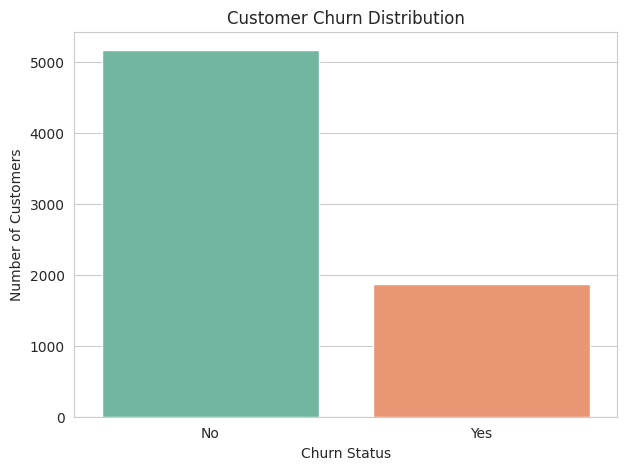

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# Create count plot
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

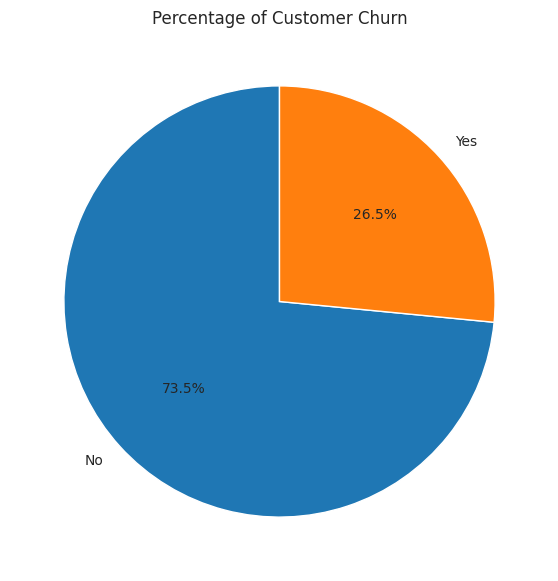

In [ ]:

# Calculate customer counts
churn_counts = df['Churn'].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage of Customer Churn')

plt.show()

In [ ]:
# Compare contract types with churn status
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn']
)

print(contract_churn)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [ ]:
# Calculate churn percentage for each contract type
contract_churn_percentage = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn_percentage)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


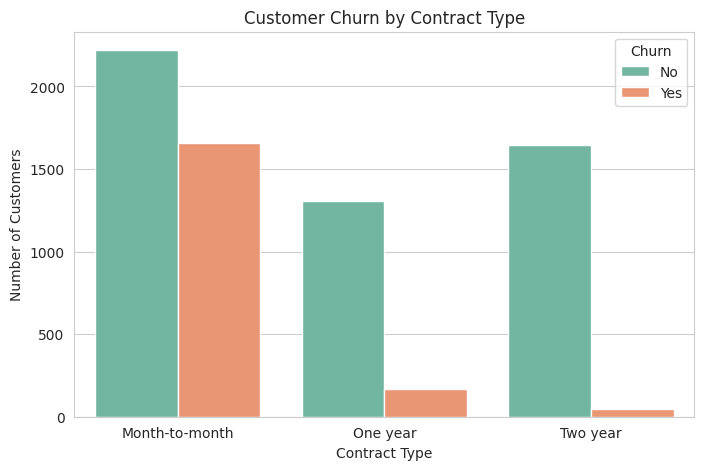

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

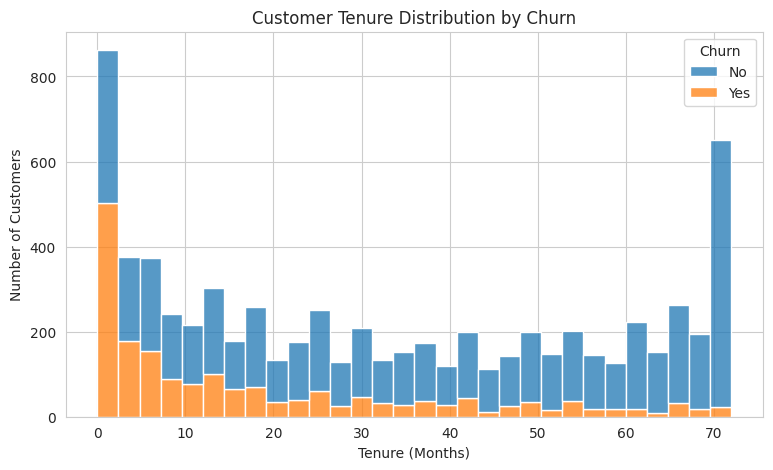

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    multiple='stack'
)

plt.title('Customer Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
print(
    df.groupby('Churn')['tenure'].mean()
)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [ ]:
# Calculate average monthly charges
print(
    df.groupby('Churn')['MonthlyCharges'].mean()
)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


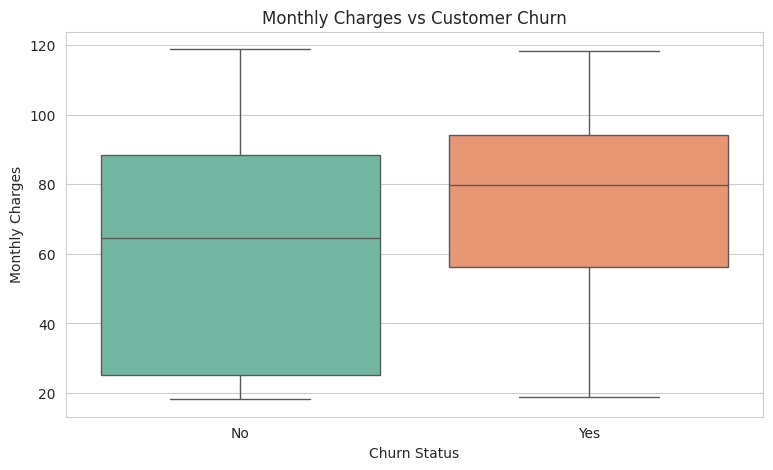

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.show()

In [ ]:
print(
    df.groupby('Churn')['TotalCharges'].mean()
)

Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64


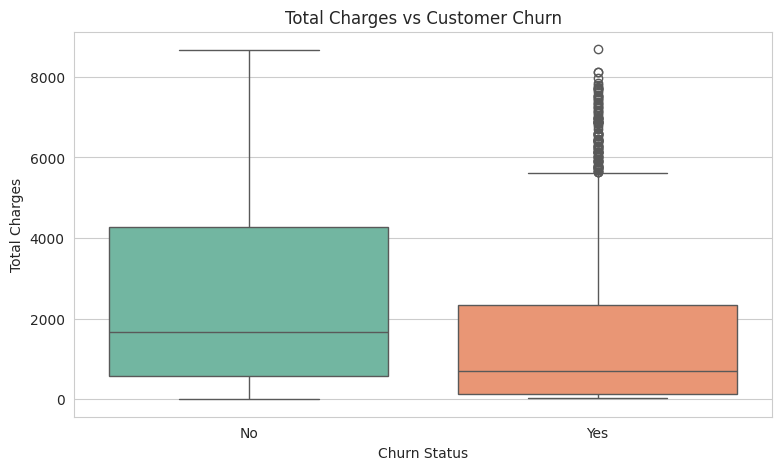

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Total Charges vs Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Total Charges')

plt.show()

In [ ]:
# Count customers by internet service and churn
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn']
)

print(internet_churn)

Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113


In [ ]:
internet_churn_percentage = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print(internet_churn_percentage)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


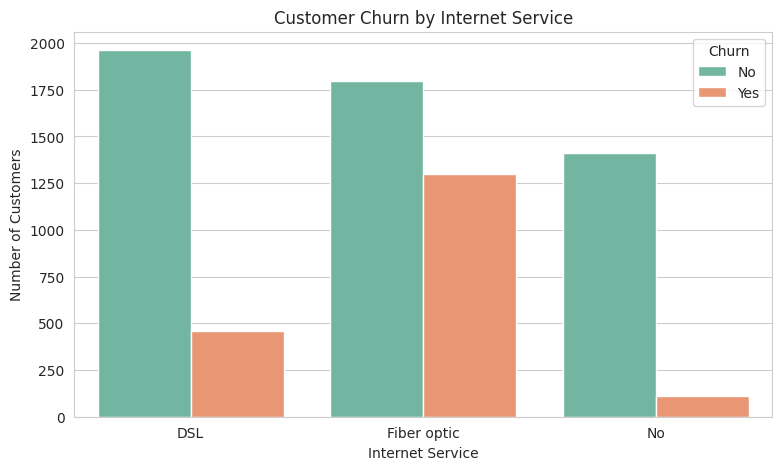

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn']
)

print(payment_churn)

Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308


In [ ]:
payment_churn_percentage = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn_percentage)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


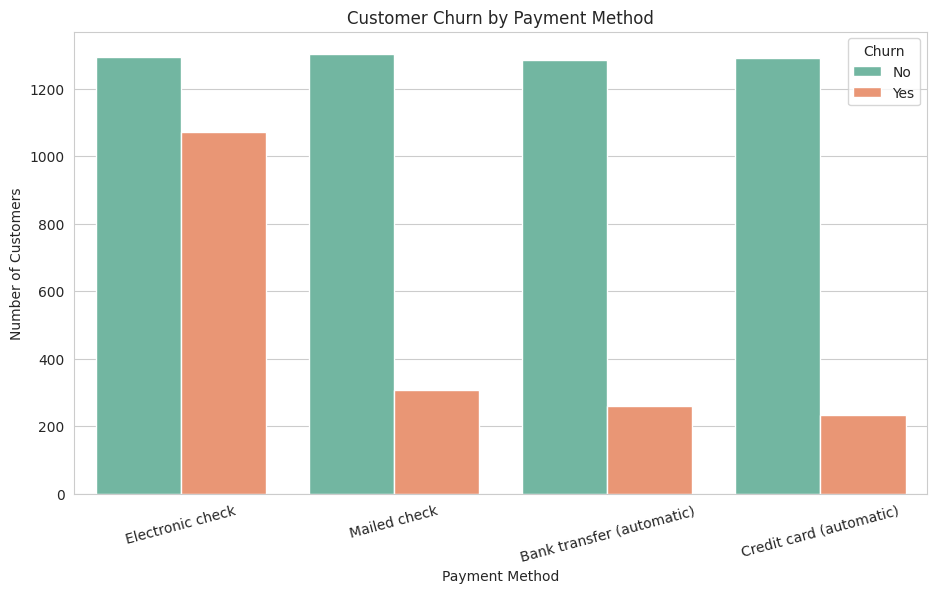

In [ ]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)

plt.show()

In [ ]:
security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn']
)

print(security_churn)

Churn                  No   Yes
OnlineSecurity                 
No                   2037  1461
No internet service  1413   113
Yes                  1724   295


In [ ]:
security_churn_percentage = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

print(security_churn_percentage)

Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194


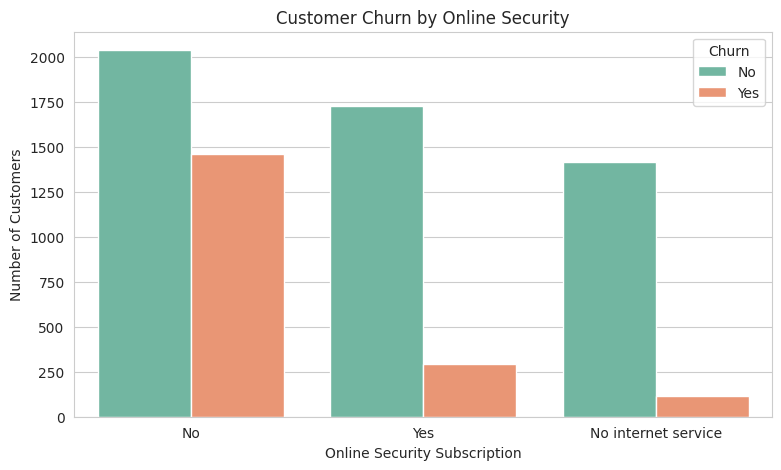

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='OnlineSecurity',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security Subscription')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
tech_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn']
)

print(tech_churn)

Churn                  No   Yes
TechSupport                    
No                   2027  1446
No internet service  1413   113
Yes                  1734   310


In [ ]:
tech_churn_percentage = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

print(tech_churn_percentage)

Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


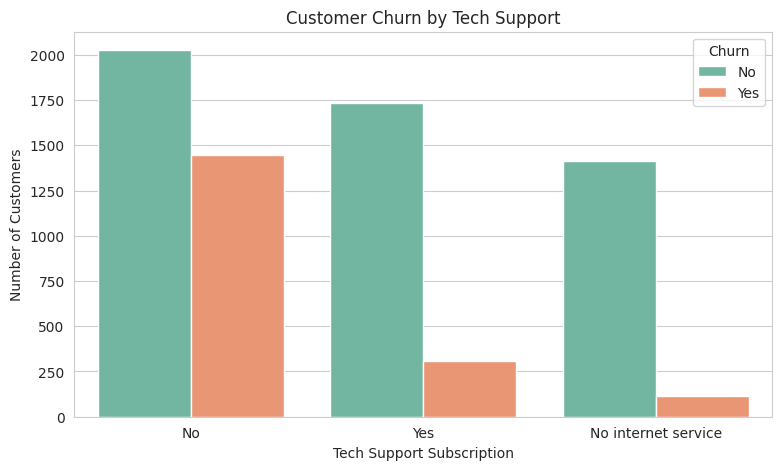

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='TechSupport',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support Subscription')
plt.ylabel('Number of Customers')

plt.show()

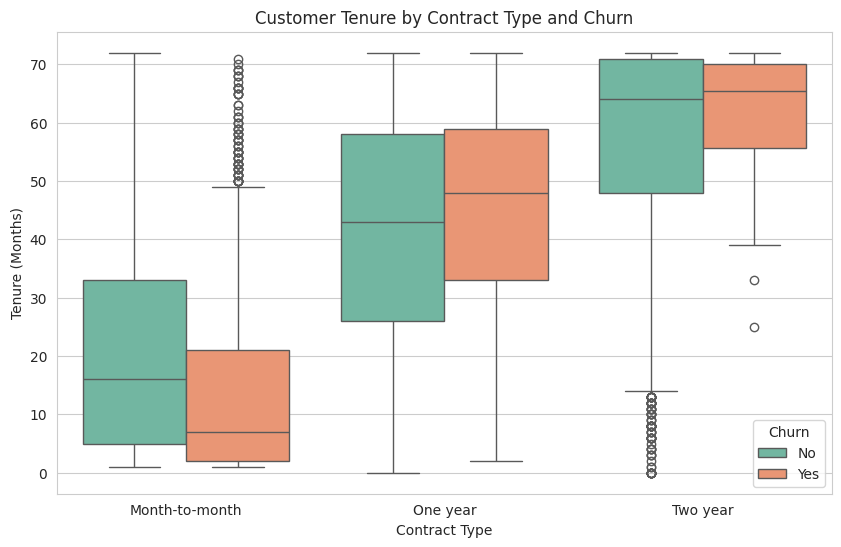

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Contract',
    y='tenure',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Tenure by Contract Type and Churn')
plt.xlabel('Contract Type')
plt.ylabel('Tenure (Months)')

plt.show()

In [ ]:
print(
    df.groupby(['Contract', 'Churn'])['tenure']
      .mean()
      .round(2)
)

Contract        Churn
Month-to-month  No       21.03
                Yes      14.02
One year        No       41.67
                Yes      44.96
Two year        No       56.60
                Yes      61.27
Name: tenure, dtype: float64


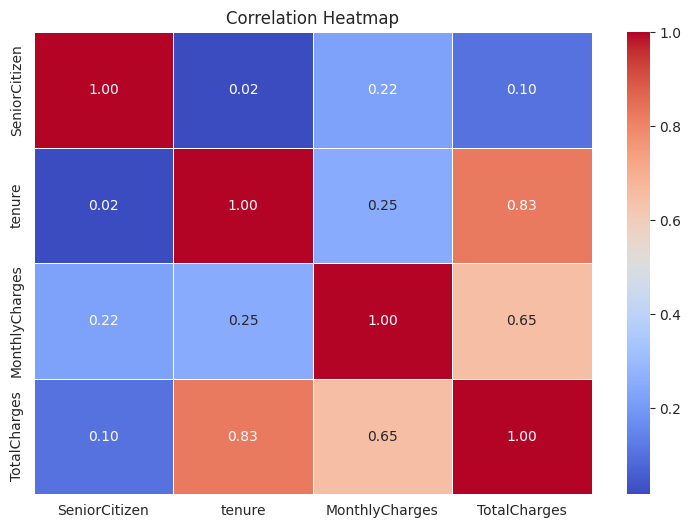

In [ ]:
# Select numerical columns
numerical_df = df[
    ['SeniorCitizen', 'tenure',
     'MonthlyCharges', 'TotalCharges']
]

# Calculate correlation
correlation = numerical_df.corr()

# Visualize correlation
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
# Create a copy of the dataset
df_model = df.copy()

# Remove customerID because it is an identifier
df_model = df_model.drop('customerID', axis=1)

# Separate features and target
X = df_model.drop('Churn', axis=1)

y = df_model['Churn'].map({
    'No': 0,
    'Yes': 1
})

# Check results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create complete ML pipeline
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict customer churn
y_pred = logistic_model.predict(X_test)

# Predict churn probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob[:10])

First 10 actual values:
[0 0 0 0 0 0 0 0 0 1]

First 10 predicted values:
[0 1 0 0 0 1 0 0 0 0]

First 10 churn probabilities:
[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:", roc_auc_score(y_test, y_prob))

Accuracy: 0.8055358410220014

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[926 109]
 [165 209]]

ROC-AUC Score: 0.8421349040274871


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            random_state=42,
            class_weight='balanced'
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

rf_pred = random_forest_model.predict(X_test)

rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nROC-AUC:",
      roc_auc_score(y_test, rf_prob))

Random Forest Accuracy: 0.7686302342086586

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409


Confusion Matrix:
[[816 219]
 [107 267]]

ROC-AUC: 0.8379007465963988


In [ ]:
import pandas as pd

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [0.8055, 0.7686],
    'Churn Precision': [0.66, 0.55],
    'Churn Recall': [0.56, 0.71],
    'Churn F1-Score': [0.60, 0.62],
    'ROC-AUC': [0.8421, 0.8379]
})

model_comparison

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-Score,ROC-AUC
0,Logistic Regression,0.8055,0.66,0.56,0.60,0.8421
1,Random Forest,0.7686,0.55,0.71,0.62,0.8379


In [ ]:
import pandas as pd

# Get the trained Random Forest classifier
rf_classifier = random_forest_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = random_forest_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Get feature importance scores
importance_scores = rf_classifier.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_scores
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
feature_importance.head(15)

,Feature,Importance
1,num__tenure,0.123953
36,cat__Contract_Month-to-month,0.107242
3,num__TotalCharges,0.106420
2,num__MonthlyCharges,0.077326
38,cat__Contract_Two year,0.059360
18,cat__OnlineSecurity_No,0.059229
27,cat__TechSupport_No,0.050502
16,cat__InternetService_Fiber optic,0.045239
43,cat__PaymentMethod_Electronic check,0.034023
21,cat__OnlineBackup_No,0.019181


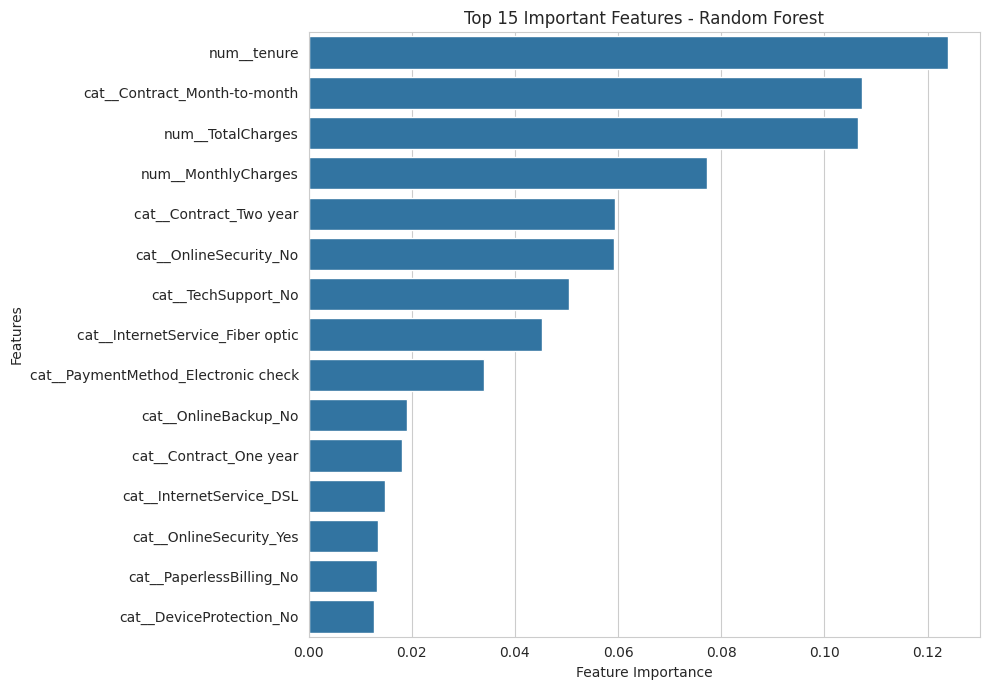

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [ ]:
# Create a copy of feature importance
grouped_importance = feature_importance.copy()

# Remove preprocessing prefixes
grouped_importance['Original_Feature'] = (
    grouped_importance['Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

# Combine one-hot encoded categories
grouped_importance['Original_Feature'] = (
    grouped_importance['Original_Feature']
    .str.split('_')
    .str[0]
)

# Sum importance of related features
grouped_importance = (
    grouped_importance
    .groupby('Original_Feature')['Importance']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_importance

,Original_Feature,Importance
0,Contract,0.184693
1,tenure,0.123953
2,TotalCharges,0.106420
3,OnlineSecurity,0.078697
4,MonthlyCharges,0.077326
5,TechSupport,0.069673
6,InternetService,0.067380
7,PaymentMethod,0.061443
8,OnlineBackup,0.033361
9,StreamingMovies,0.027519


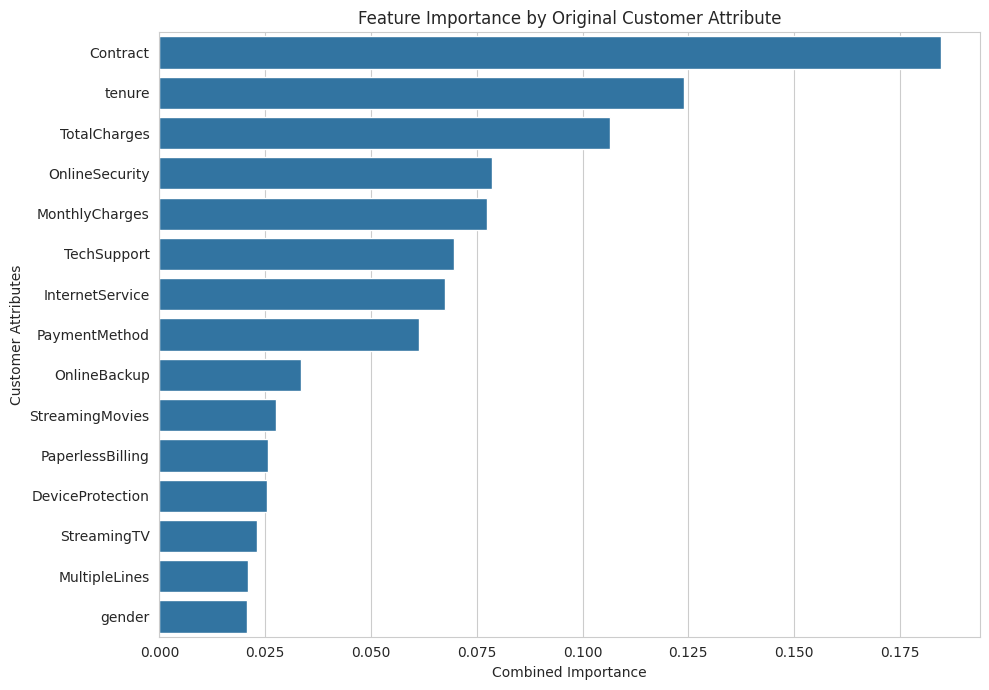

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.barplot(
    data=grouped_importance.head(15),
    x='Importance',
    y='Original_Feature'
)

plt.title('Feature Importance by Original Customer Attribute')
plt.xlabel('Combined Importance')
plt.ylabel('Customer Attributes')

plt.tight_layout()
plt.show()

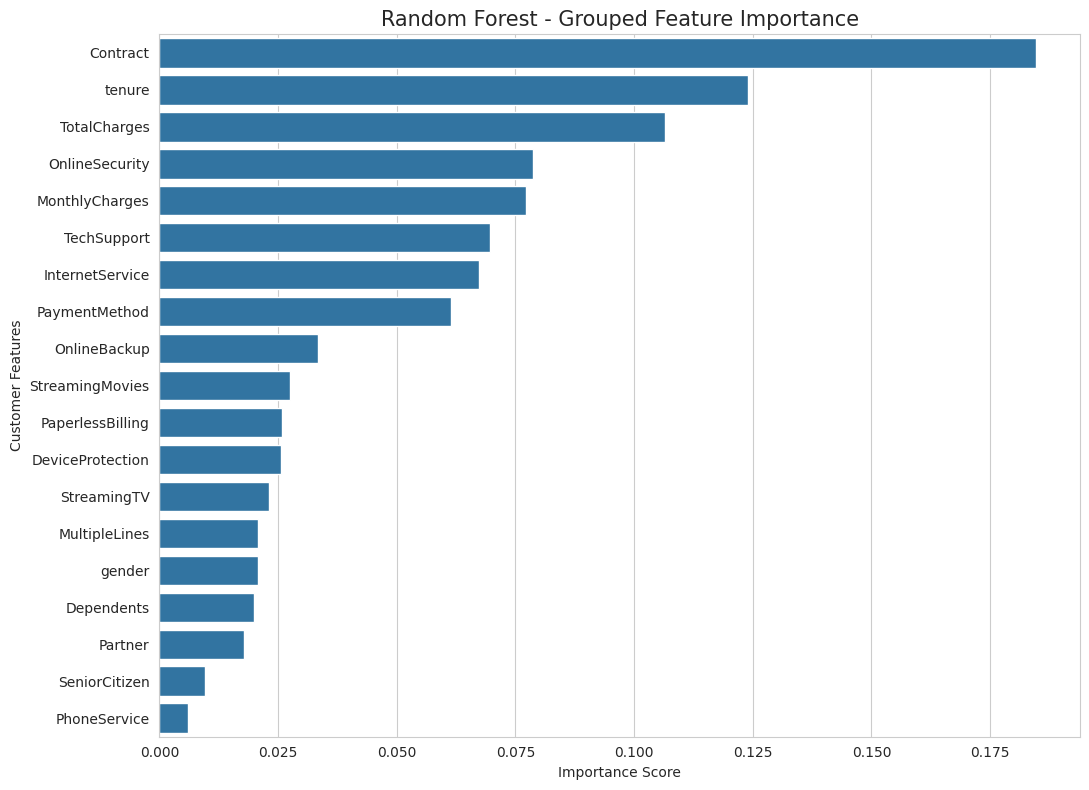

In [ ]:
plt.figure(figsize=(11, 8))

sns.barplot(
    data=grouped_importance,
    x='Importance',
    y='Original_Feature'
)

plt.title(
    'Random Forest - Grouped Feature Importance',
    fontsize=15
)

plt.xlabel('Importance Score')
plt.ylabel('Customer Features')

plt.tight_layout()
plt.show()

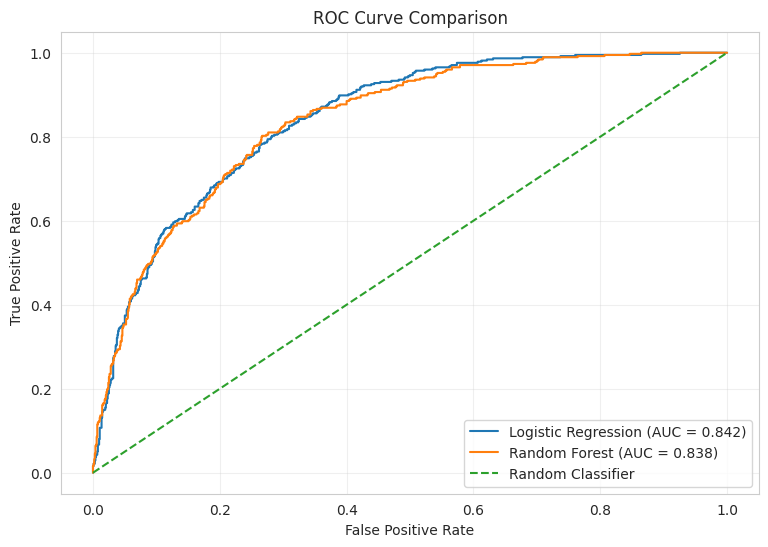

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Logistic Regression ROC
lr_fpr, lr_tpr, _ = roc_curve(y_test, y_prob)

# Random Forest ROC
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

# Calculate AUC
lr_auc = roc_auc_score(y_test, y_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f'Logistic Regression (AUC = {lr_auc:.3f})'
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve Comparison')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

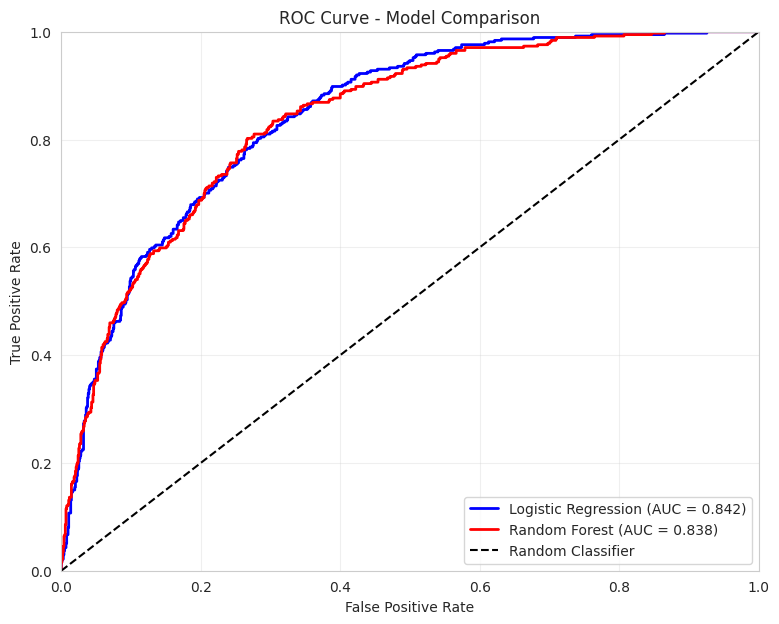

In [ ]:
plt.figure(figsize=(9, 7))

plt.plot(
    lr_fpr,
    lr_tpr,
    color='blue',
    linewidth=2,
    label=f'Logistic Regression (AUC = {lr_auc:.3f})'
)

plt.plot(
    rf_fpr,
    rf_tpr,
    color='red',
    linewidth=2,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='black',
    linestyle='--',
    label='Random Classifier'
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - Model Comparison')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

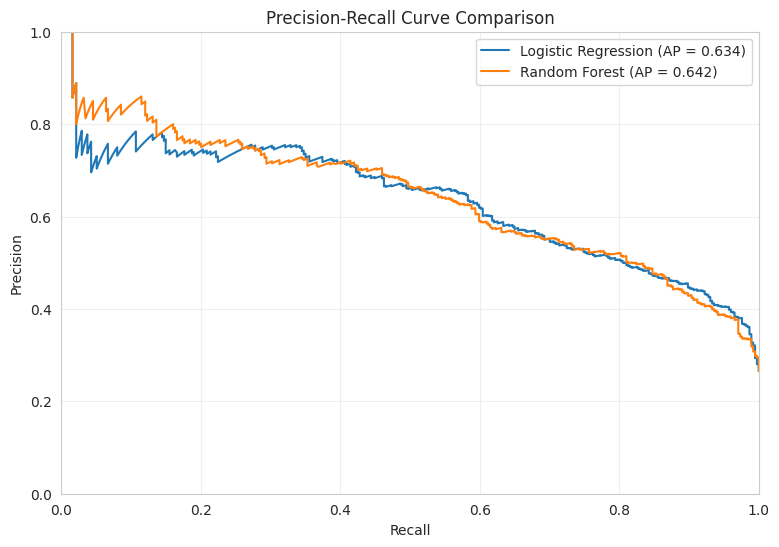

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Logistic Regression
lr_precision, lr_recall, _ = precision_recall_curve(
    y_test, y_prob
)

lr_ap = average_precision_score(y_test, y_prob)

# Random Forest
rf_precision, rf_recall, _ = precision_recall_curve(
    y_test, rf_prob
)

rf_ap = average_precision_score(y_test, rf_prob)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(
    lr_recall,
    lr_precision,
    label=f'Logistic Regression (AP = {lr_ap:.3f})'
)

plt.plot(
    rf_recall,
    rf_precision,
    label=f'Random Forest (AP = {rf_ap:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')

plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.show()

In [ ]:
print("Logistic Regression Average Precision:", lr_ap)
print("Random Forest Average Precision:", rf_ap)

Logistic Regression Average Precision: 0.6343385058492537
Random Forest Average Precision: 0.6422299180218687


In [ ]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_new.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nValidation target distribution:")
print(y_val.value_counts())

Training data: (4507, 19)
Validation data: (1127, 19)
Testing data: (1409, 19)

Validation target distribution:
Churn
0    828
1    299
Name: count, dtype: int64


In [ ]:
# Train Logistic Regression
logistic_model.fit(X_train_new, y_train_new)

# Train Random Forest
random_forest_model.fit(X_train_new, y_train_new)

print("Both models retrained successfully!")

Both models retrained successfully!


In [ ]:
# Logistic Regression probabilities
lr_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Random Forest probabilities
rf_val_prob = random_forest_model.predict_proba(X_val)[:, 1]

print("Logistic Regression probabilities:")
print(lr_val_prob[:10])

print("\nRandom Forest probabilities:")
print(rf_val_prob[:10])

Logistic Regression probabilities:
[0.19633402 0.01864361 0.05275316 0.16712534 0.25490166 0.03505654
 0.17676777 0.01422864 0.01536907 0.24499299]

Random Forest probabilities:
[0.45876773 0.05446842 0.03490042 0.22015743 0.37154575 0.05924059
 0.25492435 0.02164314 0.05342688 0.20780648]


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:

    # Logistic Regression
    lr_pred = (lr_val_prob >= threshold).astype(int)

    results.append({
        'Model': 'Logistic Regression',
        'Threshold': threshold,
        'Precision': precision_score(y_val, lr_pred, zero_division=0),
        'Recall': recall_score(y_val, lr_pred, zero_division=0),
        'F1-Score': f1_score(y_val, lr_pred, zero_division=0)
    })

    # Random Forest
    rf_pred = (rf_val_prob >= threshold).astype(int)

    results.append({
        'Model': 'Random Forest',
        'Threshold': threshold,
        'Precision': precision_score(y_val, rf_pred, zero_division=0),
        'Recall': recall_score(y_val, rf_pred, zero_division=0),
        'F1-Score': f1_score(y_val, rf_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3).to_string(index=False))

              Model  Threshold  Precision  Recall  F1-Score
Logistic Regression       0.20      0.465   0.856     0.603
      Random Forest       0.20      0.414   0.923     0.571
Logistic Regression       0.25      0.512   0.803     0.625
      Random Forest       0.25      0.449   0.893     0.597
Logistic Regression       0.30      0.545   0.756     0.633
      Random Forest       0.30      0.464   0.829     0.595
Logistic Regression       0.35      0.579   0.709     0.638
      Random Forest       0.35      0.502   0.803     0.618
Logistic Regression       0.40      0.617   0.669     0.642
      Random Forest       0.40      0.525   0.773     0.625
Logistic Regression       0.45      0.659   0.602     0.629
      Random Forest       0.45      0.543   0.753     0.631
Logistic Regression       0.50      0.694   0.545     0.610
      Random Forest       0.50      0.572   0.716     0.636
Logistic Regression       0.55      0.732   0.502     0.595
      Random Forest       0.55      0.60

In [ ]:
fine_thresholds = [
    0.36, 0.38, 0.40, 0.42, 0.44,
    0.46, 0.48, 0.50, 0.52, 0.54
]

fine_results = []

for threshold in fine_thresholds:

    for model_name, probabilities in [
        ('Logistic Regression', lr_val_prob),
        ('Random Forest', rf_val_prob)
    ]:

        predictions = (probabilities >= threshold).astype(int)

        fine_results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Precision': precision_score(
                y_val, predictions, zero_division=0
            ),
            'Recall': recall_score(
                y_val, predictions, zero_division=0
            ),
            'F1-Score': f1_score(
                y_val, predictions, zero_division=0
            )
        })

fine_df = pd.DataFrame(fine_results)

print(
    fine_df.sort_values(
        'F1-Score', ascending=False
    ).round(3).to_string(index=False)
)

              Model  Threshold  Precision  Recall  F1-Score
Logistic Regression       0.38      0.608   0.689     0.646
Logistic Regression       0.36      0.589   0.706     0.642
Logistic Regression       0.40      0.617   0.669     0.642
      Random Forest       0.46      0.556   0.753     0.639
      Random Forest       0.48      0.566   0.732     0.638
      Random Forest       0.50      0.572   0.716     0.636
      Random Forest       0.52      0.584   0.696     0.635
Logistic Regression       0.42      0.624   0.639     0.631
      Random Forest       0.54      0.591   0.672     0.629
Logistic Regression       0.44      0.644   0.612     0.628
      Random Forest       0.38      0.521   0.789     0.628
      Random Forest       0.44      0.537   0.753     0.627
      Random Forest       0.42      0.529   0.766     0.626
      Random Forest       0.40      0.525   0.773     0.625
Logistic Regression       0.46      0.664   0.589     0.624
      Random Forest       0.36      0.50

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Selected thresholds from validation
lr_threshold = 0.38
rf_threshold = 0.46

# Generate probabilities on untouched test data
lr_test_prob = logistic_model.predict_proba(X_test)[:, 1]
rf_test_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Apply selected thresholds
lr_test_pred = (lr_test_prob >= lr_threshold).astype(int)
rf_test_pred = (rf_test_prob >= rf_threshold).astype(int)

# Logistic Regression evaluation
print("========== LOGISTIC REGRESSION ==========")
print("Threshold:", lr_threshold)
print("Accuracy:", accuracy_score(y_test, lr_test_pred))
print("\nClassification Report:")
print(classification_report(y_test, lr_test_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, lr_test_prob))
print("Average Precision:",
      average_precision_score(y_test, lr_test_prob))


# Random Forest evaluation
print("\n========== RANDOM FOREST ==========")
print("Threshold:", rf_threshold)
print("Accuracy:", accuracy_score(y_test, rf_test_pred))
print("\nClassification Report:")
print(classification_report(y_test, rf_test_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_test_prob))
print("Average Precision:",
      average_precision_score(y_test, rf_test_prob))

========== LOGISTIC REGRESSION ==========
Threshold: 0.38
Accuracy: 0.7757274662881476

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      1035
           1       0.56      0.69      0.62       374

    accuracy                           0.78      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion Matrix:
[[836 199]
 [117 257]]
ROC-AUC: 0.8426541631145211
Average Precision: 0.6325494936998669

========== RANDOM FOREST ==========
Threshold: 0.46
Accuracy: 0.7537260468417317

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82      1035
           1       0.53      0.73      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.75      0.76      1409

Confusion Matrix:
[[78

In [ ]:
def predict_customer_churn(customer_data):

    # Convert customer information into a DataFrame
    customer_df = pd.DataFrame([customer_data])

    # Predict churn probability
    churn_probability = logistic_model.predict_proba(
        customer_df
    )[0][1]

    # Apply selected threshold
    threshold = 0.38

    if churn_probability >= threshold:
        prediction = "Yes - Customer Likely to Churn"
    else:
        prediction = "No - Customer Likely to Stay"

    return {
        "Churn Prediction": prediction,
        "Churn Probability": round(churn_probability * 100, 2),
        "Threshold": threshold
    }

In [ ]:
sample_customer = {
    'gender': 'Male',
    'SeniorCitizen': 0,
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': 2,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 85.0,
    'TotalCharges': 170.0
}

result = predict_customer_churn(sample_customer)

print("Prediction Result:")
for key, value in result.items():
    print(f"{key}: {value}")

Prediction Result:
Churn Prediction: Yes - Customer Likely to Churn
Churn Probability: 62.06
Threshold: 0.38


In [ ]:
import joblib

# Save model and threshold together
model_artifact = {
    'model': logistic_model,
    'threshold': 0.38,
    'model_name': 'Logistic Regression',
    'target': 'Churn'
}

joblib.dump(
    model_artifact,
    'customer_churn_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [1]:
import time
import os
from google.colab import files

# Ensure the file exists on disk and is completely written before downloading
file_path = '/content/customer_churn_model.pkl'

if os.path.exists(file_path):
    print("File found! Initiating download...")
    files.download(file_path)
else:
    # Fallback to current working directory name if path is different
    fallback_path = 'customer_churn_model.pkl'
    if os.path.exists(fallback_path):
        print("File found in working directory! Initiating download...")
        files.download(fallback_path)
    else:
        print("Error: The model file 'customer_churn_model.pkl' could not be found. Please re-run the save model cell (wbAnxD1SSDQJ) first.")

FileNotFoundError: Cannot find file: customer_churn_model.pkl

In [ ]:
import joblib
import pandas as pd

# Load saved model
loaded_artifact = joblib.load('customer_churn_model.pkl')

loaded_model = loaded_artifact['model']
loaded_threshold = loaded_artifact['threshold']

print("Model loaded successfully!")
print("Model:", loaded_artifact['model_name'])
print("Threshold:", loaded_threshold)

Model loaded successfully!
Model: Logistic Regression
Threshold: 0.38


In [ ]:
# Predict using the loaded model
probability = loaded_model.predict_proba(
    pd.DataFrame([sample_customer])
)[0][1]

prediction = (
    "Yes - Likely to Churn"
    if probability >= loaded_threshold
    else "No - Likely to Stay"
)

print("Prediction:", prediction)
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: Yes - Likely to Churn
Churn Probability: 62.06 %


In [ ]:
import sklearn
import pandas as pd
import joblib
import numpy as np

print("Python ML libraries information")
print("--------------------------------")
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Joblib:", joblib.__version__)

print("\nSaved model information")
print("-----------------------")
print("Model:", loaded_artifact['model_name'])
print("Threshold:", loaded_artifact['threshold'])
print("Model type:", type(loaded_model).__name__)

Python ML libraries information
--------------------------------
Scikit-learn: 1.6.1
Pandas: 2.2.3
NumPy: 2.4.6
Joblib: 1.6.0

Saved model information
-----------------------
Model: Logistic Regression
Threshold: 0.38
Model type: Pipeline


## Summary of Analysis & Model Performance

### 1. Key Business Insights from EDA
* **Contract Type:** Customers with **Month-to-month** contracts are at a significantly higher risk of churning (**42.7%**) compared to those on One-year (**11.3%**) or Two-year (**2.8%**) contracts.
* **Tenure:** Customers who churned had a much shorter average tenure (**~18 months**) compared to those who stayed (**~38 months**).
* **Charges:** Higher Monthly Charges correlate with higher churn; the average monthly charge for churned customers is **$74.44** versus **$61.27** for retained customers.
* **Internet Service & Tech Support:** Customers using **Fiber optic** internet services have a high churn rate (**41.9%**). Conversely, customers with **Online Security** or **Tech Support** subscriptions are highly likely to remain with the company.
* **Payment Method:** The **Electronic Check** payment method is strongly associated with churn (**45.3%**).

### 2. Model Performance Comparison (Default Threshold 0.50)

| Model | Accuracy | Churn Precision | Churn Recall | Churn F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | 80.55% | 0.66 | 0.56 | 0.60 | 0.8421 |
| **Random Forest** | 76.86% | 0.55 | 0.71 | 0.62 | 0.8379 |

### 3. Optimized Model Performance (After Threshold Tuning)
By leveraging the Validation set, we identified custom classification thresholds to optimize the F1-Score (balancing precision and recall for the churn class):
* **Logistic Regression (Threshold = 0.38):**
  * **F1-Score:** 0.62
  * **Recall:** 0.69 (Captured 69% of actual churners)
  * **Precision:** 0.56
* **Random Forest (Threshold = 0.46):**
  * **F1-Score:** 0.61
  * **Recall:** 0.73 (Captured 73% of actual churners)
  * **Precision:** 0.53

### 4. Saved Model Artifacts
* **Saved File:** `customer_churn_model.pkl` containing the optimized **Logistic Regression** Pipeline and its customized classification threshold (**0.38**).